# Part 1: Python, Pandas Basics & Matplotlib Fundamentals
**Course Notes Reference:** Parts 2, 3 & 6 (`Complete_Data_Visualization_Notes.pdf`)

Topics covered:
1. Standard imports & loading `vgsales.csv`
2. Pandas essentials & data cleaning (*Golden Rule: Clean first, plot second*)
3. NumPy helpers for plotting (`linspace`, `arange`, `random.normal`, `log1p`)
4. Matplotlib basic line plot & customization (`color`, `linestyle`, `linewidth`, `marker`, `alpha`, `label`)
5. Labels, title, grid, ticks, axis limits, legend & `tight_layout()`
6. Two Matplotlib styles: `pyplot` (state-based) vs Object-Oriented (`fig, ax = plt.subplots()`)
7. Subplots (multiple charts in one figure)
8. Built-in styles, colormaps (`cmap`), colorbar & saving figures (`plt.savefig`)


In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

data = pd.read_csv("vgsales.csv")
data.head()


## 1. Pandas Essentials & Data Cleaning (Clean First, Plot Second)


In [2]:
print("Shape:", data.shape)
print("\nMissing values per column:\n", data.isnull().sum())
print("\nDuplicate rows:", data.duplicated().sum())
data.info()


Shape: (16598, 11)

Missing values per column:
 Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

Duplicate rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), ob

In [3]:
# Clean missing values in Year and Publisher, and fix Year dtype
df = data.dropna(subset=["Year", "Publisher"]).copy()
df["Year"] = df["Year"].astype(int)
print("Cleaned shape:", df.shape)
df.describe()


Cleaned shape: (16291, 11)


In [4]:
# Quick aggregations & sorting used before plotting
print("Top 5 games by Global_Sales:")
display(df.sort_values("Global_Sales", ascending=False).head(5)[["Name", "Platform", "Year", "Genre", "Global_Sales"]])

print("\nTotal Global_Sales by Genre:")
display(df.groupby("Genre")["Global_Sales"].sum().sort_values(ascending=False))


Top 5 games by Global_Sales:

Total Global_Sales by Genre:


                       Name Platform  Year         Genre  Global_Sales
0                Wii Sports      Wii  2006        Sports         82.74
1         Super Mario Bros.      NES  1985      Platform         40.24
2            Mario Kart Wii      Wii  2008        Racing         35.82
3         Wii Sports Resort      Wii  2009        Sports         33.00
4  Pokemon Red/Pokemon Blue       GB  1996  Role-Playing         31.37

Genre
Action          1722.84
Sports          1309.24
Shooter         1026.20
Role-Playing     923.83
Platform         829.13
Misc             789.87
Racing           726.76
Fighting         444.05
Simulation       389.98
Puzzle           242.21
Adventure        234.59
Strategy         173.27
Name: Global_Sales, dtype: float64

## 2. NumPy Helpers for Plotting


In [5]:
x_smooth = np.linspace(0, 10, 100)   # 100 evenly spaced points for smooth curves
x_seq = np.arange(1, 8)              # 1, 2, 3, 4, 5, 6, 7
rand_norm = np.random.normal(0, 1, 500)
log_sales = np.log1p(df["Global_Sales"])

print("linspace sample:", x_smooth[:5])
print("arange:", x_seq)
print("log1p min/max:", round(log_sales.min(), 3), round(log_sales.max(), 3))


linspace sample: [0.        0.1010101 0.2020202 0.3030303 0.4040404]
arange: [1 2 3 4 5 6 7]
log1p min/max: 0.01 4.428


## 3. Basic Line Plot & Customizations


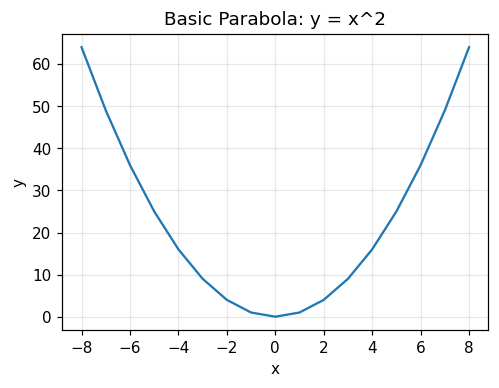

In [6]:
# Basic plot (from original notebook)
x_val = [-8, -7, -6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]
y_val = [64, 49, 36, 25, 16, 9, 4, 1, 0, 1, 4, 9, 16, 25, 36, 49, 64]

plt.figure(figsize=(5, 3.5))
plt.plot(x_val, y_val)
plt.title("Basic Parabola: y = x^2")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.show()


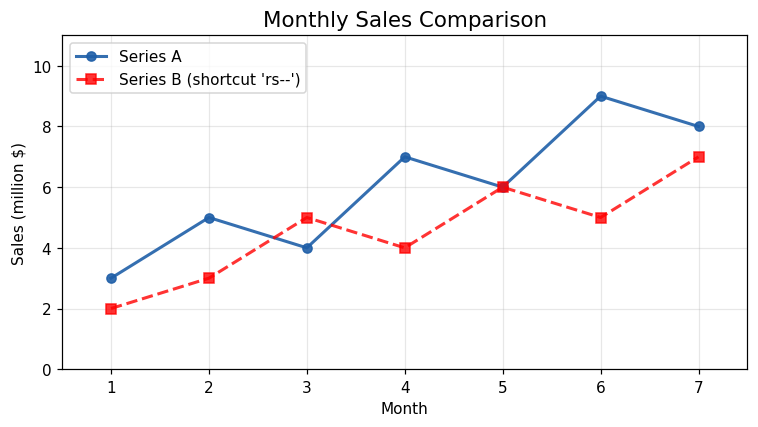

In [7]:
# Customizing line style, color, marker, linewidth, alpha, legend, ticks & limits
x = np.arange(1, 8)
y1 = [3, 5, 4, 7, 6, 9, 8]
y2 = [2, 3, 5, 4, 6, 5, 7]

plt.figure(figsize=(7, 4))
plt.plot(x, y1, color="#1f5fa8", linestyle="-", linewidth=2, marker="o", markersize=6, alpha=0.9, label="Series A")
plt.plot(x, y2, "rs--", linewidth=2, markersize=6, alpha=0.8, label="Series B (shortcut 'rs--')")

plt.title("Monthly Sales Comparison", fontsize=14)
plt.xlabel("Month")
plt.ylabel("Sales (million $)")
plt.xticks(x, rotation=0)
plt.xlim(0.5, 7.5)
plt.ylim(0, 11)
plt.grid(True, alpha=0.3)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()


## 4. Object-Oriented (OO) Style vs `pyplot` Style


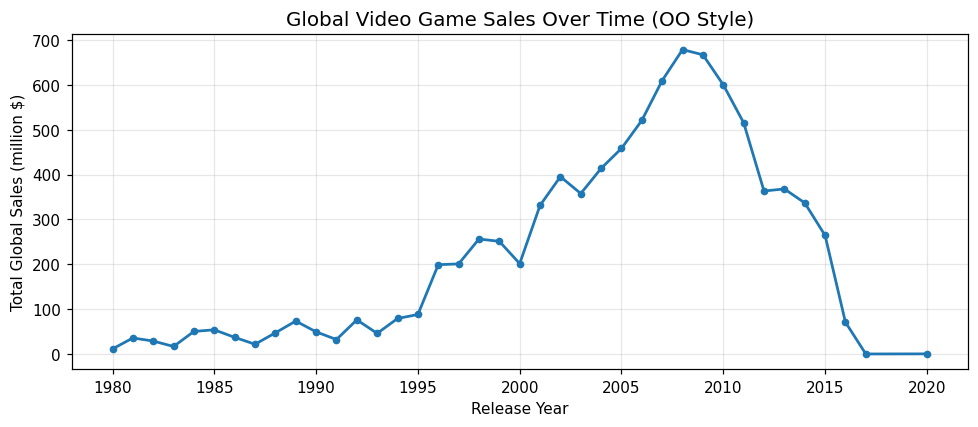

In [8]:
# Recommended OO style for real projects and multiple plots
yearly_sales = df.groupby("Year")["Global_Sales"].sum()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(yearly_sales.index, yearly_sales.values, color="tab:blue", marker="o", markersize=4, linewidth=1.8)
ax.set_title("Global Video Game Sales Over Time (OO Style)", fontsize=13)
ax.set_xlabel("Release Year")
ax.set_ylabel("Total Global Sales (million $)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 5. Subplots: Many Charts in One Figure


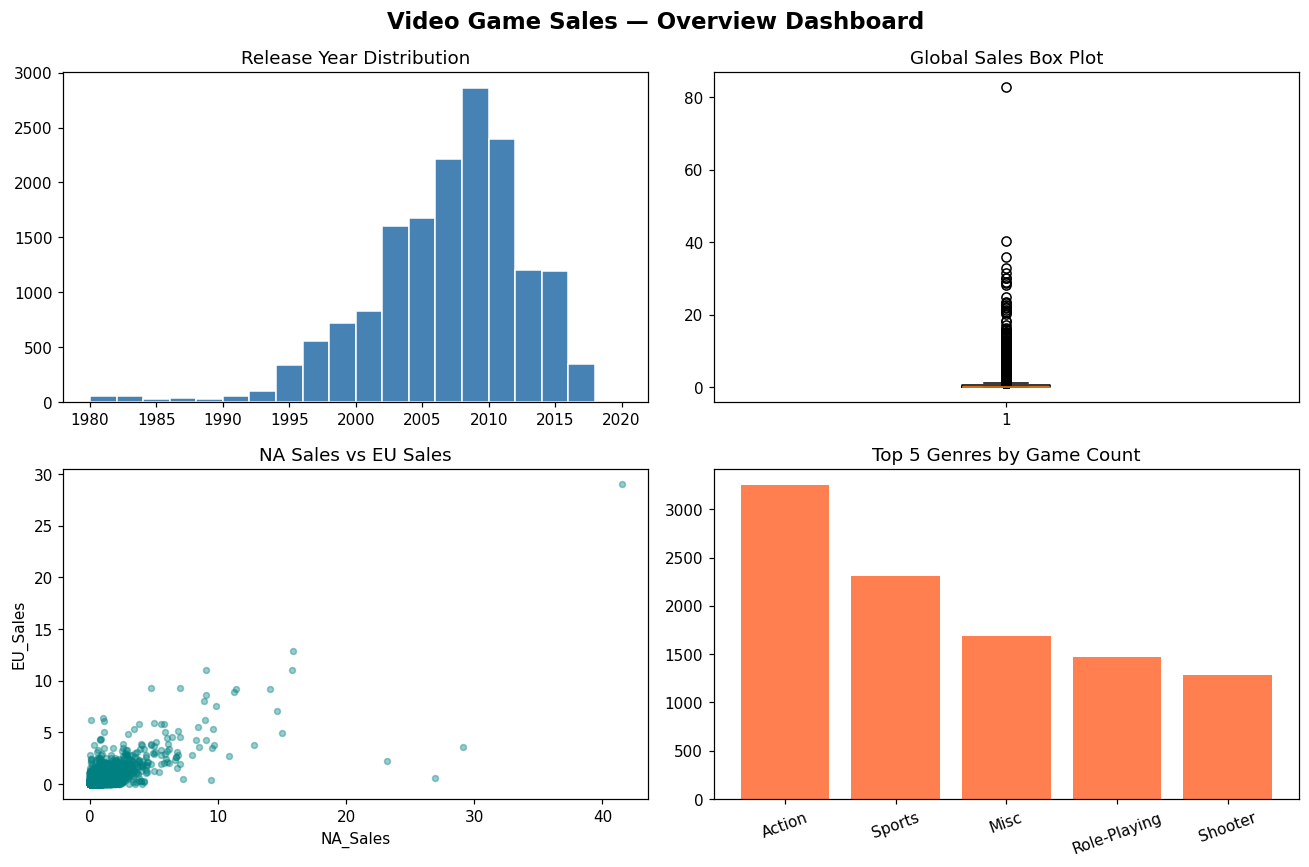

In [9]:
top5_genres = df["Genre"].value_counts().head(5)

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))

axes[0, 0].hist(df["Year"], bins=20, color="steelblue", edgecolor="white")
axes[0, 0].set_title("Release Year Distribution")

axes[0, 1].boxplot(df["Global_Sales"])
axes[0, 1].set_title("Global Sales Box Plot")

axes[1, 0].scatter(df["NA_Sales"], df["EU_Sales"], alpha=0.4, s=15, color="teal")
axes[1, 0].set_title("NA Sales vs EU Sales")
axes[1, 0].set_xlabel("NA_Sales")
axes[1, 0].set_ylabel("EU_Sales")

axes[1, 1].bar(top5_genres.index, top5_genres.values, color="coral")
axes[1, 1].set_title("Top 5 Genres by Game Count")
axes[1, 1].tick_params(axis="x", rotation=20)

fig.suptitle("Video Game Sales — Overview Dashboard", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()


## 6. Styles, Colormaps (`cmap`) & Saving Figures


Sample available styles: ['Solarize_Light2', '_classic_test_patch', '_mpl-gallery', '_mpl-gallery-nogrid', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot']


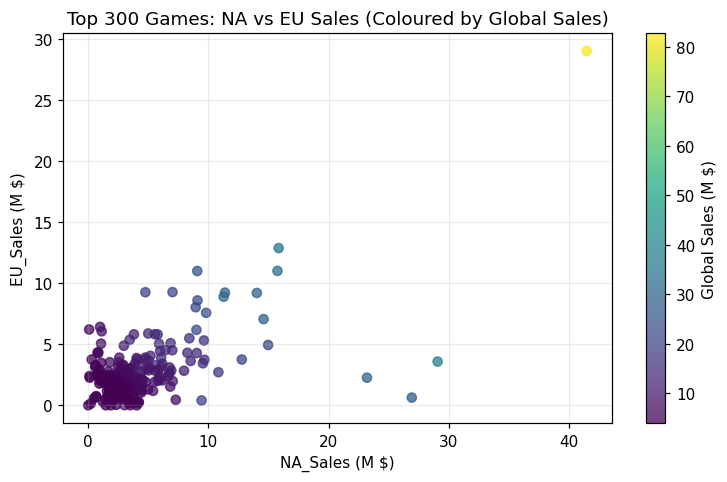

In [10]:
print("Sample available styles:", plt.style.available[:10])

# Colour each scatter point by Global_Sales using viridis colormap
sample = df.head(300)
plt.figure(figsize=(7, 4.5))
sc = plt.scatter(sample["NA_Sales"], sample["EU_Sales"], c=sample["Global_Sales"], cmap="viridis", alpha=0.75)
plt.colorbar(sc, label="Global Sales (M $)")
plt.title("Top 300 Games: NA vs EU Sales (Coloured by Global Sales)")
plt.xlabel("NA_Sales (M $)")
plt.ylabel("EU_Sales (M $)")
plt.grid(alpha=0.25)
plt.tight_layout()
# Example: savefig must be called BEFORE plt.show()
# plt.savefig("na_vs_eu_viridis.png", dpi=300, bbox_inches="tight")
plt.show()
